# Análisis visual de distribuciones y outliers: producción del campo Volve

**Objetivo:** caracterizar las variables de un dataset real de producción petrolera: ver la forma de sus distribuciones (asimetría y curtosis), compararlas entre categorías y detectar valores atípicos (*outliers*) con gráficos y con la regla del rango intercuartílico (IQR).

**Origen de los datos:** producción diaria del campo petrolero Volve (Mar del Norte), publicada por Equinor. Se usó la copia disponible en [Kaggle](https://www.kaggle.com/datasets/nazarmahadialseied/volve-field-production-dataset-oil-and-gas), guardada en `data/volve_produccion.csv`. Tiene 15.634 registros diarios de 7 pozos entre 2007 y 2016.

**Variables principales:**

| Variable | Tipo | Descripción |
|---|---|---|
| `NPD_WELL_BORE_NAME` | categórica | Nombre del pozo |
| `FLOW_KIND` | categórica | `production` (produce) o `injection` (inyecta agua) |
| `BORE_OIL_VOL` | numérica | Petróleo producido en el día |
| `BORE_WAT_VOL` | numérica | Agua producida en el día |
| `ON_STREAM_HRS` | numérica | Horas del día en que el pozo estuvo operando |
| `AVG_WHP_P` | numérica | Presión promedio en cabeza de pozo |
| `AVG_DOWNHOLE_PRESSURE` | numérica | Presión promedio de fondo de pozo |

## 1. Carga y revisión inicial

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

RUTA_DATOS = "data/volve_produccion.csv"
datos = pd.read_csv(RUTA_DATOS, parse_dates=["DATEPRD"])

print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (15634, 16)


,DATEPRD,NPD_WELL_BORE_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND
0,2014-04-07,15/9-F-1 C,0.0,0.000,0.000,0.000,0.0,0.00000,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production
1,2014-04-08,15/9-F-1 C,0.0,NaN,NaN,NaN,0.0,1.00306,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production
2,2014-04-09,15/9-F-1 C,0.0,NaN,NaN,NaN,0.0,0.97901,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production
3,2014-04-10,15/9-F-1 C,0.0,NaN,NaN,NaN,0.0,0.54576,0.000,0.00,0.000,0.0,0.0,0.0,NaN,production
4,2014-04-11,15/9-F-1 C,0.0,310.376,96.876,277.278,0.0,1.21599,33.098,10.48,33.072,0.0,0.0,0.0,NaN,production


In [2]:
# Valores nulos por columna (solo mostramos las que tienen)
nulos = datos.isna().sum()
nulos[nulos > 0]

ON_STREAM_HRS                285
AVG_DOWNHOLE_PRESSURE       6654
AVG_DOWNHOLE_TEMPERATURE    6654
AVG_DP_TUBING               6654
AVG_ANNULUS_PRESS           7744
AVG_CHOKE_SIZE_P            6715
AVG_WHP_P                   6479
AVG_WHT_P                   6488
DP_CHOKE_SIZE                294
BORE_OIL_VOL                6473
BORE_GAS_VOL                6473
BORE_WAT_VOL                6473
BORE_WI_VOL                 9928
dtype: int64

## 2. Limpieza y preparación

Las filas de `injection` corresponden a pozos que inyectan agua para mantener la presión del yacimiento: no producen petróleo (su `BORE_OIL_VOL` está vacío). Como el análisis de distribuciones y outliers se centra en la **producción**, se trabaja con las filas `production`. Los nulos que quedan son de sensores (presiones y temperaturas) y se excluyen variable por variable al calcular estadísticos y gráficos.

In [3]:
produccion = datos[datos["FLOW_KIND"] == "production"].copy()

print("Registros totales:", len(datos))
print("Registros de producción:", len(produccion))
print("Nulos en BORE_OIL_VOL (producción):", produccion["BORE_OIL_VOL"].isna().sum())

Registros totales: 15634
Registros de producción: 9161
Nulos en BORE_OIL_VOL (producción): 0


## 3. Variables categóricas: gráficos de barras

Primero se mira cuántos registros hay por pozo y por tipo de flujo, y después cuánto petróleo produce en promedio cada pozo.

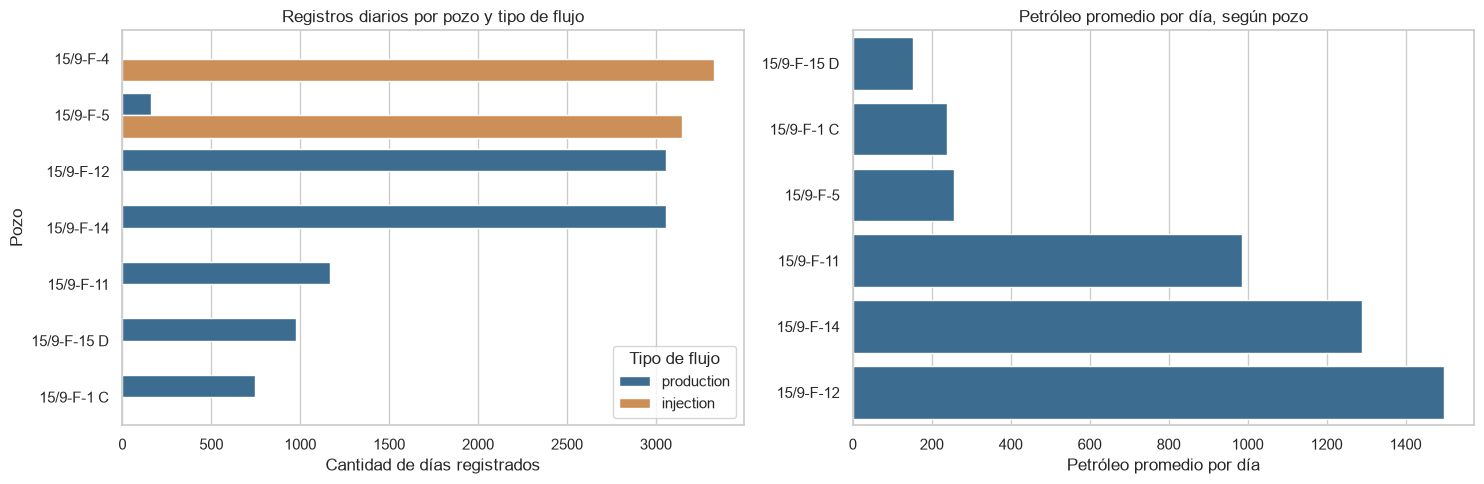

In [4]:
orden_pozos = datos["NPD_WELL_BORE_NAME"].value_counts().index

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))

# Barras 1: cantidad de registros por pozo, separado por tipo de flujo
sns.countplot(
    data=datos, y="NPD_WELL_BORE_NAME", hue="FLOW_KIND", order=orden_pozos,
    palette={"production": "#2E6F9E", "injection": "#E08E45"}, ax=ejes[0],
)
ejes[0].set_title("Registros diarios por pozo y tipo de flujo")
ejes[0].set_xlabel("Cantidad de días registrados")
ejes[0].set_ylabel("Pozo")
ejes[0].legend(title="Tipo de flujo")

# Barras 2: petróleo promedio por día de cada pozo productor
promedio_petroleo = (
    produccion.groupby("NPD_WELL_BORE_NAME")["BORE_OIL_VOL"].mean().sort_values()
)
sns.barplot(
    x=promedio_petroleo.values, y=promedio_petroleo.index,
    color="#2E6F9E", ax=ejes[1],
)
ejes[1].set_title("Petróleo promedio por día, según pozo")
ejes[1].set_xlabel("Petróleo promedio por día")
ejes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Lectura:** los pozos `15/9-F-4` y `15/9-F-5` son sobre todo inyectores. Entre los productores, `15/9-F-12` y `15/9-F-14` tienen más del doble de días registrados que los demás (3.056 contra entre 160 y 1.165) y los mayores promedios de producción diaria (1.499 y 1.290). Esta diferencia de escala entre pozos va a ser clave más adelante para interpretar los outliers.

## 4. Forma de la distribución: asimetría (skewness) y curtosis

- **Asimetría positiva** (> 0): la cola larga está a la **derecha** (pocos valores muy altos). **Asimetría negativa** (< 0): la cola larga está a la **izquierda** (pocos valores muy bajos).
- **Curtosis** (se usa el *exceso de curtosis*, donde 0 equivale a una distribución normal): valores positivos indican colas más pesadas (más valores extremos que una normal); valores negativos, colas más livianas y una distribución más "aplanada".

In [5]:
variables_numericas = [
    "BORE_OIL_VOL", "BORE_WAT_VOL", "ON_STREAM_HRS",
    "AVG_WHP_P", "AVG_DOWNHOLE_PRESSURE",
]


def interpretar_asimetria(valor):
    # Umbral habitual: entre -0.5 y 0.5 se considera aproximadamente simétrica
    if valor > 0.5:
        return "positiva (cola a la derecha)"
    if valor < -0.5:
        return "negativa (cola a la izquierda)"
    return "aproximadamente simétrica"


forma_distribucion = pd.DataFrame({
    "media": produccion[variables_numericas].mean(),
    "mediana": produccion[variables_numericas].median(),
    "desvio_estandar": produccion[variables_numericas].std(),
    "asimetria": produccion[variables_numericas].skew(),
    "curtosis": produccion[variables_numericas].kurt(),  # pandas devuelve el exceso de curtosis
}).round(2)
forma_distribucion["interpretacion_asimetria"] = forma_distribucion["asimetria"].apply(
    interpretar_asimetria
)
forma_distribucion

,media,mediana,desvio_estandar,asimetria,curtosis,interpretacion_asimetria
BORE_OIL_VOL,1095.64,558.00,1323.54,1.67,2.00,positiva (cola a la derecha)
BORE_WAT_VOL,1672.15,1098.00,1706.98,0.52,-1.19,positiva (cola a la derecha)
ON_STREAM_HRS,20.17,24.00,8.29,-1.87,1.69,negativa (cola a la izquierda)
AVG_WHP_P,45.38,37.93,24.75,0.91,0.96,positiva (cola a la derecha)
AVG_DOWNHOLE_PRESSURE,181.80,232.90,109.71,-0.95,-0.86,negativa (cola a la izquierda)


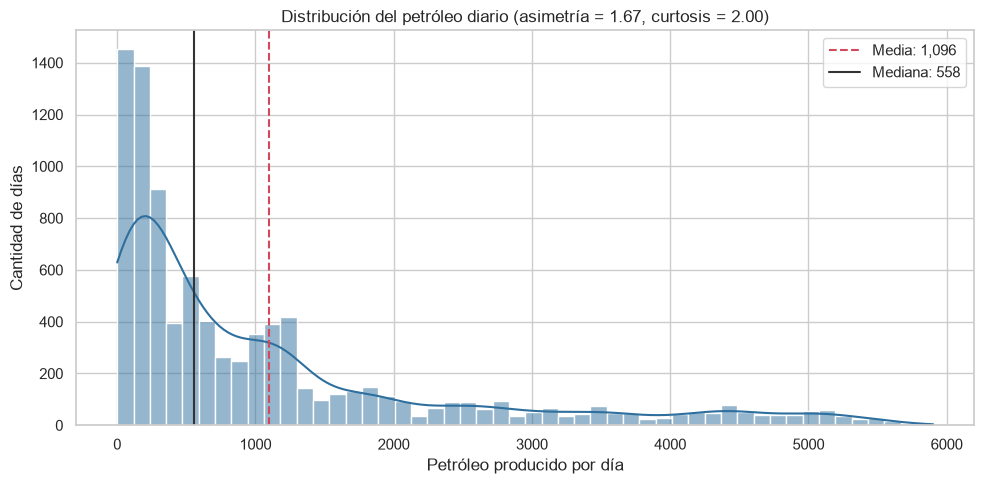

In [6]:
# Histograma del petróleo diario con su media y su mediana
petroleo = produccion["BORE_OIL_VOL"]

fig, eje = plt.subplots(figsize=(10, 5))
sns.histplot(petroleo, bins=50, kde=True, color="#2E6F9E", ax=eje)
eje.axvline(petroleo.mean(), color="#D1495B", linestyle="--", label=f"Media: {petroleo.mean():,.0f}")
eje.axvline(petroleo.median(), color="#333333", linestyle="-", label=f"Mediana: {petroleo.median():,.0f}")
eje.set_title(
    f"Distribución del petróleo diario (asimetría = {petroleo.skew():.2f}, "
    f"curtosis = {petroleo.kurt():.2f})"
)
eje.set_xlabel("Petróleo producido por día")
eje.set_ylabel("Cantidad de días")
eje.legend()
plt.tight_layout()
plt.show()

**Lectura:** el petróleo diario tiene **asimetría positiva (1,67)**: la mayoría de los días la producción es baja o moderada y hay pocos días de producción muy alta, que estiran la cola hacia la derecha. Por eso la media (1.096) queda por encima de la mediana (558). La curtosis positiva (2,00) indica colas más pesadas que una normal, es decir, más días extremos de lo esperable. También se ve una acumulación de días en 0: son días en que el pozo estuvo cerrado.

Otras formas: `ON_STREAM_HRS` tiene asimetría **negativa** (-1,87) porque casi todos los días el pozo opera 24 horas y los pocos días con menos horas forman la cola izquierda; `AVG_DOWNHOLE_PRESSURE` también es negativa (-0,95), por los días con el pozo cerrado y presión 0.

## 5. Visualización de outliers: boxplot y violin plot

Se compara el petróleo diario entre pozos con un **boxplot** (los puntos fuera de los bigotes son candidatos a outlier) y con un **violin plot** (muestra además la forma completa de la distribución de cada pozo). En el boxplot se marca el límite superior de la regla IQR calculado con todos los datos juntos (se calcula en la sección 6).

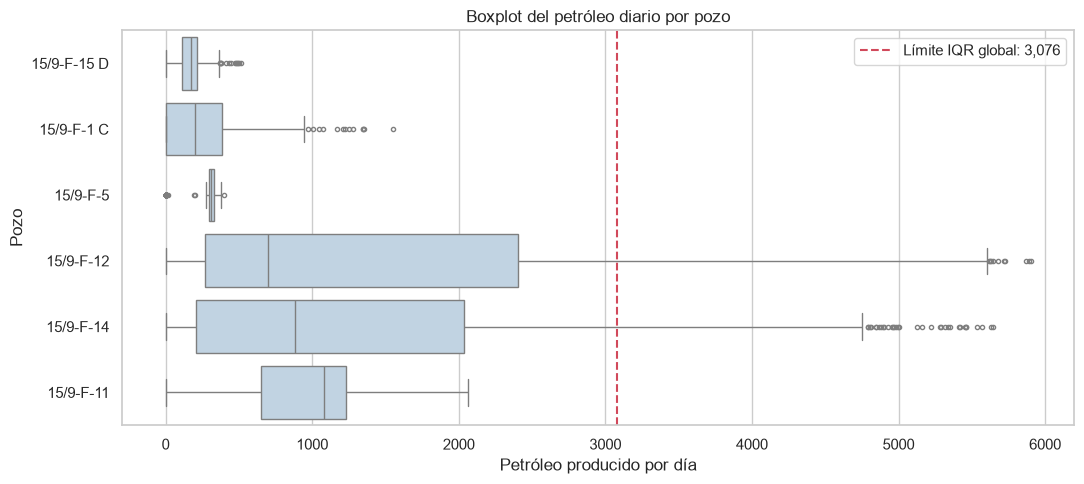

In [7]:
def calcular_limites_iqr(serie, factor=1.5):
    """Devuelve (limite_inferior, limite_superior) según la regla del IQR.

    Q1 y Q3 son los cuartiles 25% y 75%; IQR = Q3 - Q1.
    Se considera outlier todo valor fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR].
    """
    cuartil_1 = serie.quantile(0.25)
    cuartil_3 = serie.quantile(0.75)
    rango_intercuartil = cuartil_3 - cuartil_1
    return (
        cuartil_1 - factor * rango_intercuartil,
        cuartil_3 + factor * rango_intercuartil,
    )


limite_inf_global, limite_sup_global = calcular_limites_iqr(produccion["BORE_OIL_VOL"])
orden_por_mediana = (
    produccion.groupby("NPD_WELL_BORE_NAME")["BORE_OIL_VOL"].median().sort_values().index
)

fig, eje = plt.subplots(figsize=(11, 5))
sns.boxplot(
    data=produccion, x="BORE_OIL_VOL", y="NPD_WELL_BORE_NAME", order=orden_por_mediana,
    color="#BBD3E8", fliersize=3, ax=eje,
)
eje.axvline(
    limite_sup_global, color="#D1495B", linestyle="--",
    label=f"Límite IQR global: {limite_sup_global:,.0f}",
)
eje.set_title("Boxplot del petróleo diario por pozo")
eje.set_xlabel("Petróleo producido por día")
eje.set_ylabel("Pozo")
eje.legend()
plt.tight_layout()
plt.show()

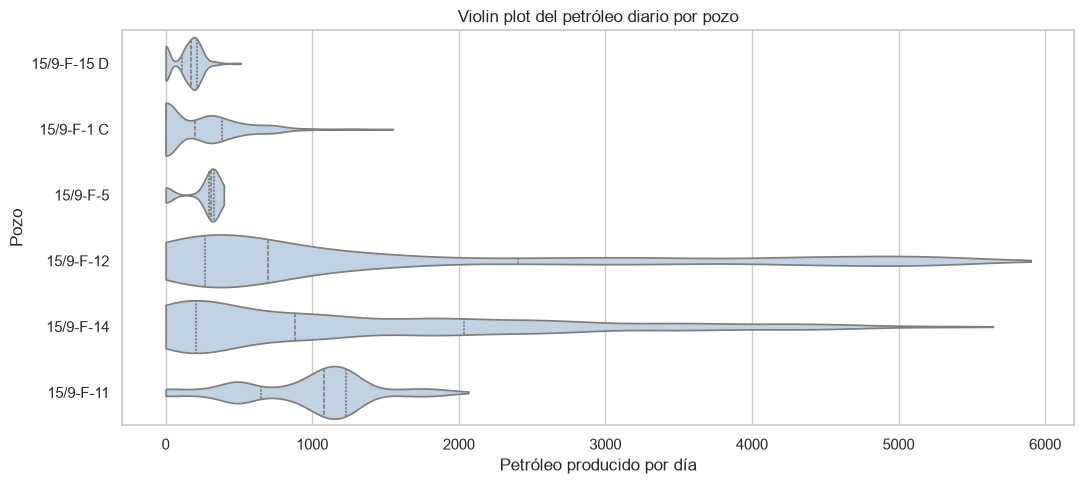

In [8]:
fig, eje = plt.subplots(figsize=(11, 5))
sns.violinplot(
    data=produccion, x="BORE_OIL_VOL", y="NPD_WELL_BORE_NAME", order=orden_por_mediana,
    color="#BBD3E8", inner="quartile", cut=0, density_norm="width", ax=eje,
)
eje.set_title("Violin plot del petróleo diario por pozo")
eje.set_xlabel("Petróleo producido por día")
eje.set_ylabel("Pozo")
plt.tight_layout()
plt.show()

**Lectura:** cada pozo tiene su propia escala. `15/9-F-12` y `15/9-F-14` tienen cajas mucho más anchas y colas largas hacia la derecha, mientras que `15/9-F-1 C`, `15/9-F-15 D` y `15/9-F-5` trabajan en rangos bajos. La línea roja (límite calculado con todos los pozos mezclados) solo es superada por puntos de `15/9-F-12` y `15/9-F-14`. Los violines de varios pozos muestran además una zona de densidad pegada a 0: los días de pozo cerrado.

## 6. Detección de outliers con la regla IQR

Se detectan outliers de dos formas, para ver cómo cambia el resultado:
1. **Global:** un solo límite calculado con todos los pozos juntos.
2. **Por pozo:** un límite propio para cada pozo (segmentando por `NPD_WELL_BORE_NAME`).

In [9]:
def marcar_outliers_iqr(tabla, columna, por=None, factor=1.5):
    """Devuelve una serie booleana: True si el registro es outlier según IQR.

    Si se indica `por`, los límites se calculan por separado para cada grupo.
    """
    if por is None:
        limite_inf, limite_sup = calcular_limites_iqr(tabla[columna].dropna(), factor)
        return (tabla[columna] < limite_inf) | (tabla[columna] > limite_sup)

    es_outlier = pd.Series(False, index=tabla.index)
    for grupo, subtabla in tabla.groupby(por):
        limite_inf, limite_sup = calcular_limites_iqr(subtabla[columna].dropna(), factor)
        es_outlier.loc[subtabla.index] = (
            (subtabla[columna] < limite_inf) | (subtabla[columna] > limite_sup)
        )
    return es_outlier


produccion["outlier_global"] = marcar_outliers_iqr(produccion, "BORE_OIL_VOL")
produccion["outlier_por_pozo"] = marcar_outliers_iqr(
    produccion, "BORE_OIL_VOL", por="NPD_WELL_BORE_NAME"
)

print(f"Límites IQR globales: [{limite_inf_global:,.0f} ; {limite_sup_global:,.0f}]")
print(f"Outliers con límite global: {produccion['outlier_global'].sum()} "
      f"({produccion['outlier_global'].mean():.1%} de los registros)")
print(f"Outliers con límite por pozo: {produccion['outlier_por_pozo'].sum()} "
      f"({produccion['outlier_por_pozo'].mean():.1%} de los registros)")

Límites IQR globales: [-1,540 ; 3,076]
Outliers con límite global: 986 (10.8% de los registros)
Outliers con límite por pozo: 105 (1.1% de los registros)


In [10]:
# Segmentación de los outliers por pozo
resumen_outliers = produccion.groupby("NPD_WELL_BORE_NAME").agg(
    registros=("BORE_OIL_VOL", "size"),
    outliers_globales=("outlier_global", "sum"),
    outliers_por_pozo=("outlier_por_pozo", "sum"),
)
resumen_outliers

,registros,outliers_globales,outliers_por_pozo
NPD_WELL_BORE_NAME,,,
15/9-F-1 C,746,0,13
15/9-F-11,1165,0,0
15/9-F-12,3056,621,10
15/9-F-14,3056,365,34
15/9-F-15 D,978,0,13
15/9-F-5,160,0,35


In [11]:
# Segmentación por dirección: valores por encima ("alto") o por debajo ("bajo")
# de los límites IQR de cada pozo
produccion["tipo_outlier"] = "normal"
for pozo, subtabla in produccion.groupby("NPD_WELL_BORE_NAME"):
    limite_inf, limite_sup = calcular_limites_iqr(subtabla["BORE_OIL_VOL"])
    produccion.loc[subtabla.index[subtabla["BORE_OIL_VOL"] > limite_sup], "tipo_outlier"] = "alto"
    produccion.loc[subtabla.index[subtabla["BORE_OIL_VOL"] < limite_inf], "tipo_outlier"] = "bajo"

direccion = pd.crosstab(produccion["NPD_WELL_BORE_NAME"], produccion["tipo_outlier"])
print(direccion[["alto", "bajo"]].sum().to_string())
print()

# ¿Cómo son los outliers bajos? (todos los que tienen producción 0)
outliers_bajos = produccion[produccion["tipo_outlier"] == "bajo"]
print(f"Outliers bajos: {len(outliers_bajos)} | con producción 0: "
      f"{(outliers_bajos['BORE_OIL_VOL'] == 0).sum()} | pozos: "
      f"{outliers_bajos['NPD_WELL_BORE_NAME'].unique().tolist()}")
direccion[["alto", "bajo"]]

tipo_outlier
alto    71
bajo    34

Outliers bajos: 34 | con producción 0: 31 | pozos: ['15/9-F-5']


tipo_outlier,alto,bajo
NPD_WELL_BORE_NAME,,
15/9-F-1 C,13,0
15/9-F-11,0,0
15/9-F-12,10,0
15/9-F-14,34,0
15/9-F-15 D,13,0
15/9-F-5,1,34


In [12]:
# Listado de los registros outlier más extremos (límite por pozo)
columnas_listado = ["DATEPRD", "NPD_WELL_BORE_NAME", "BORE_OIL_VOL", "ON_STREAM_HRS"]
(
    produccion[produccion["outlier_por_pozo"]]
    .sort_values("BORE_OIL_VOL", ascending=False)[columnas_listado]
    .head(10)
)

,DATEPRD,NPD_WELL_BORE_NAME,BORE_OIL_VOL,ON_STREAM_HRS
2240,2009-01-08,15/9-F-12,5902.0,24.0
2385,2009-06-03,15/9-F-12,5889.0,24.0
2242,2009-01-10,15/9-F-12,5870.0,24.0
2235,2009-01-03,15/9-F-12,5727.0,24.0
2243,2009-01-11,15/9-F-12,5717.0,24.0
2329,2009-04-07,15/9-F-12,5678.0,24.0
2241,2009-01-09,15/9-F-12,5644.0,24.0
5548,2009-09-20,15/9-F-14,5644.0,24.0
5364,2009-03-17,15/9-F-14,5634.0,24.0
2237,2009-01-05,15/9-F-12,5629.0,24.0


**Lectura:** con un límite global hay **986 outliers (10,8%)**, y todos pertenecen a `15/9-F-12` y `15/9-F-14`. No son datos raros: esos dos pozos producen a otra escala que el resto, y el límite global los penaliza por ser distintos. Cuando se calcula un límite propio para cada pozo, los outliers bajan a **105 (1,1%)**: **71 picos altos** y **34 valores bajos**. Los 10 picos más extremos son todos de 2009 y de `15/9-F-12` o `15/9-F-14`.

Los 34 valores bajos son todos de `15/9-F-5` y 31 de ellos son días con producción 0. Ese pozo mantiene una producción diaria en un rango angosto, así que un día en 0 es atípico *para él*, algo que el análisis global no mostraba.

### Valores imposibles que la regla IQR no detecta

La regla IQR solo mira la dispersión de los datos, no si un valor tiene sentido físico. Conviene revisar dos variables con reglas del dominio.

In [13]:
# 1) Un día tiene como máximo 24 horas: ¿hay registros que lo superan?
horas_imposibles = produccion[produccion["ON_STREAM_HRS"] > 24][
    ["DATEPRD", "NPD_WELL_BORE_NAME", "ON_STREAM_HRS"]
].sort_values("DATEPRD")
horas_imposibles["dia_semana"] = horas_imposibles["DATEPRD"].dt.day_name()

# ¿Todas caen en el último domingo de octubre (cambio de hora en Europa)?
es_ultimo_domingo_octubre = (
    (horas_imposibles["DATEPRD"].dt.month == 10)
    & (horas_imposibles["DATEPRD"].dt.dayofweek == 6)
    & (horas_imposibles["DATEPRD"].dt.day >= 25)
)
print(f"Registros con más de 24 horas: {len(horas_imposibles)}")
print(f"¿Todos en el último domingo de octubre?: {es_ultimo_domingo_octubre.all()}")
horas_imposibles

Registros con más de 24 horas: 13
¿Todos en el último domingo de octubre?: True


,DATEPRD,NPD_WELL_BORE_NAME,ON_STREAM_HRS,dia_semana
2166,2008-10-26,15/9-F-12,25.00,Sunday
5222,2008-10-26,15/9-F-14,25.00,Sunday
2527,2009-10-25,15/9-F-12,24.83,Sunday
5583,2009-10-25,15/9-F-14,24.50,Sunday
2891,2010-10-31,15/9-F-12,25.00,Sunday
5947,2010-10-31,15/9-F-14,25.00,Sunday
856,2013-10-27,15/9-F-11,24.31,Sunday
3912,2013-10-27,15/9-F-12,24.14,Sunday
6968,2013-10-27,15/9-F-14,24.31,Sunday
202,2014-10-26,15/9-F-1 C,25.00,Sunday


In [14]:
# 2) El agua producida no puede ser negativa
agua_negativa = produccion[produccion["BORE_WAT_VOL"] < 0][
    ["DATEPRD", "NPD_WELL_BORE_NAME", "BORE_WAT_VOL", "BORE_OIL_VOL"]
]
limite_inf_agua, limite_sup_agua = calcular_limites_iqr(produccion["BORE_WAT_VOL"].dropna())
print(f"Registros con agua negativa: {len(agua_negativa)}")
print(f"Límites IQR del agua: [{limite_inf_agua:,.0f} ; {limite_sup_agua:,.0f}] "
      "-> la regla IQR no los marca como outliers")
agua_negativa

Registros con agua negativa: 4
Límites IQR del agua: [-4,842 ; 8,122] -> la regla IQR no los marca como outliers


,DATEPRD,NPD_WELL_BORE_NAME,BORE_WAT_VOL,BORE_OIL_VOL
1982,2008-04-23,15/9-F-12,-14.0,2736.0
3502,2012-08-13,15/9-F-12,-458.0,633.0
5350,2009-03-03,15/9-F-14,-1.0,4339.0
6558,2012-08-13,15/9-F-14,-59.0,203.0


In [15]:
# 3) Días con el pozo cerrado: no son outliers, pero concentran valores en 0
dias_cerrados = (produccion["ON_STREAM_HRS"] == 0).sum()
print(f"Días con 0 horas de operación: {dias_cerrados} "
      f"({dias_cerrados / len(produccion):.1%} de los registros de producción)")

operando = produccion[produccion["ON_STREAM_HRS"] > 0]["BORE_OIL_VOL"]
print(f"Asimetría del petróleo (todos los días): {produccion['BORE_OIL_VOL'].skew():.2f}")
print(f"Asimetría del petróleo (solo días operando): {operando.skew():.2f}")

Días con 0 horas de operación: 1141 (12.5% de los registros de producción)
Asimetría del petróleo (todos los días): 1.67
Asimetría del petróleo (solo días operando): 1.55


## 7. Conclusiones y decisiones sobre los outliers

| Hallazgo | ¿Es un error? | Decisión |
|---|---|---|
| **Picos de petróleo** (986 con límite global; 71 picos altos con límite por pozo) | No. Son producciones altas reales, sobre todo de `15/9-F-12` y `15/9-F-14` al inicio de su vida productiva. | **Conservarlos.** Detectarlos por pozo y no con un límite global. Si el modelo es sensible a la asimetría, **transformar** la variable (por ejemplo, logaritmo de 1 + valor) en lugar de eliminarla. |
| **Más de 24 horas de operación** (13 registros, todos en el último domingo de octubre) | No. Ese día la hora retrocede y el día dura 25 horas. | **Conservar** y documentar, o **limitar a 24** si el modelo asume un máximo diario. |
| **Agua negativa** (4 registros, hasta -458) | Sí, es físicamente imposible (probable error de medición o de asignación). La regla IQR no los detecta. | **Reemplazar por nulo** y completarlo con una imputación (o con 0 en los valores cercanos a 0). |
| **Días con 0 horas de operación** (12,5% de los registros; incluye 31 de los 34 outliers bajos de `15/9-F-5`) | No. Son días con el pozo cerrado. | **No eliminar**, pero **marcarlos** con una columna indicadora, o analizar por separado los días operando (la asimetría del petróleo baja de 1,67 a 1,55). |

**Idea central:** un outlier no es automáticamente un dato malo. Antes de eliminar un valor conviene preguntar si tiene una explicación física o de negocio, y si el límite se calculó sobre un grupo homogéneo. Acá, segmentar por pozo cambió el resultado de 986 a 105 outliers, y mostró un patrón distinto: los días en 0 de `15/9-F-5`.